# Inversion Methods Compared on Four Geometries

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/inversion_methods.ipynb)

[`streamfunction_from_vorticity`](xref:api#sesmax_core.streamfunction_from_vorticity) inverts the Helmholtz relation $(\nabla^2 - \lambda)\,\psi = f$ with one of four methods: a spectral DST, conjugate gradients (CG), a capacitance-matrix correction, or CG preconditioned by a multigrid V-cycle. This notebook runs each method that applies on four domains of increasing difficulty, a rectangle, a basin with a land border, a circular basin and a notch with a variable coefficient, and compares accuracy and cost.

**What you'll learn:**

1. Which `method=` fits which geometry, and what each needs (a mask, a pre-built gridax solver).
2. How to read CG iteration counts and residuals directly from gaussx, with and without a preconditioner.
3. Where the wrapper stops: a variable coefficient $c(x, y)$ is outside `sesmax_core.gfd`, so the notch uses the gridax multigrid solver on its own.
4. How to pass known boundary values with `known_values=`.

## The discrete operator

On a uniform grid with spacings $\Delta x, \Delta y$ the Laplacian is the five-point stencil

$$\nabla^2_h \psi_{j,i} = \frac{\psi_{j,i+1} - 2\psi_{j,i} + \psi_{j,i-1}}{\Delta x^2} + \frac{\psi_{j+1,i} - 2\psi_{j,i} + \psi_{j-1,i}}{\Delta y^2}$$

and the discrete Helmholtz operator is $A\psi = \nabla^2_h \psi - \lambda\,\psi$. The methods differ in how they invert $A$.

| Method | Mechanism | Needs | Handles masks? | Variable coefficient? |
|--------|-----------|-------|:-:|:-:|
| `"spectral"` | Eigenvalue division after a DST | nothing | No | No |
| `"capacitance"` | Spectral solve plus a correction at the coast points | `capacitance_solver` from gridax | Yes | No |
| `"cg"` | Krylov iteration (gaussx) with a spectral preconditioner | `mask` | Yes | No |
| `"multigrid"` | CG preconditioned by one multigrid V-cycle | `mask` and `multigrid_solver` from gridax | Yes | Not through the wrapper |

The spectral solve, the CG and the preconditioning come from sesmax (the methods), and the pieces built from the grid and the mask (the capacitance matrix, the multigrid hierarchy) come from gridax.

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

In [2]:
import time
import warnings

import gaussx
import gridax_jax
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import minimum_filter

import sesmax_core.gfd as gfd


warnings.filterwarnings("ignore", message=r".*IProgress.*")
jax.config.update("jax_enable_x64", True)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark",
        "-v -m -p numpy,matplotlib,jax,gaussx,gridax_jax,sesmax_core",
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

numpy      : 2.4.4
matplotlib : 3.11.2
jax        : 0.12.0.1
gaussx     : 0.8.1
gridax_jax : 0.3.0
sesmax_core: 0.1.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Shared Setup

### Grid

The grid is $64 \times 64$ ψ nodes on the unit square, small enough that the whole notebook runs in a few minutes on a CPU. On the C-grid the walls of the rectangle are the nodes $0$ and $N-2$, so $\Delta x = \Delta y = 1/(N-2)$. We use $\lambda = 4$: a positive $\lambda$ keeps the operator away from the Poisson null space and the system well conditioned, yet small enough that the Laplacian still dominates. All timings in this notebook are at this size; for larger grids the methods separate further.

### Right-hand side

The source is $f = \sin(\pi x)\sin(\pi y)$ on the nodes, multiplied by the wet mask. On the rectangle it is a DST eigenvector, which makes the spectral solve exact and CG very fast; on the masked domains it is no longer an eigenvector.

### Helpers

`plot_row` draws the right-hand side, the solution and the residual $f - A\hat\psi$ side by side. The residual panel hides the outermost wet layer, where the stencil reads the dry zeros and leaves a boundary-layer artefact. `time_fn` jit-compiles a zero-argument callable, warms it up, and averages the wall-clock time over several calls. `cg` runs gaussx CG on a negative-definite operator and returns the solution and the solver info.

In [4]:
N = 64
dx = dy = 1.0 / (N - 2)
lambda_ = 4.0

Y, X = np.mgrid[:N, :N]
rhs = jnp.sin(jnp.pi * Y / (N - 2)) * jnp.sin(jnp.pi * X / (N - 2))

print(f"Grid: {N}x{N},  dx={dx:.4f},  lambda={lambda_}")

Grid: 64x64,  dx=0.0161,  lambda=4.0


In [5]:
RTOL = ATOL = 1e-6  # the wrapper's CG tolerances


def laplace_op(mask):
    """The masked Helmholtz operator of a wet mask, the one `method="cg"` solves."""
    m = jnp.asarray(mask)
    return lambda x: gridax_jax.masked_laplacian(x, m, dx, dy, lambda_=lambda_)


def cg(matvec, b, preconditioner=None, rtol=RTOL, atol=ATOL):
    """gaussx CG on a negative-definite operator, as the wrapper runs it."""
    op = gaussx.as_linear_operator(
        matvec,
        in_structure=jax.ShapeDtypeStruct(b.shape, b.dtype),
        negative_definite=True,
    )
    # gaussx solves (-A) x = -b, so it takes -M^-1
    pc = None if preconditioner is None else (lambda r: -preconditioner(r))
    solver = gaussx.CGSolver(rtol=rtol, atol=atol, max_steps=500)
    return gaussx.linear_solve_with_info(op, b, solver=solver, preconditioner=pc)


def time_fn(fn, warmup=1, repeats=5):
    """Jit, warm up, then time `repeats` calls (seconds)."""
    jitted = jax.jit(fn)
    for _ in range(warmup):
        jitted().block_until_ready()
    t0 = time.perf_counter()
    for _ in range(repeats):
        jitted().block_until_ready()
    return (time.perf_counter() - t0) / repeats


def rel_residual(sol, b, matvec, mask):
    """||b - A sol|| / ||b|| on the wet cells."""
    r = (b - matvec(sol)) * mask
    return float(jnp.linalg.norm(r) / jnp.linalg.norm(b * mask))


def plot_row(b, sol, err, mask, title):
    """RHS | solution | residual on the wet cells (outer wet layer hidden)."""
    inner = minimum_filter(np.asarray(mask), size=3)
    fields = [
        (np.where(mask > 0.5, np.asarray(b), np.nan), "RHS $f$"),
        (np.where(mask > 0.5, np.asarray(sol), np.nan), "Solution $\\hat\\psi$"),
        (np.where(inner > 0.5, np.asarray(err), np.nan), "Residual $f - A\\hat\\psi$"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(8, 2.4), dpi=50)
    for k, (ax, (field, name)) in enumerate(zip(axes, fields, strict=True)):
        lim = np.nanmax(np.abs(field)) or 1.0
        v = {"vmin": -lim, "vmax": lim} if k == 2 else {}
        im = ax.imshow(field, origin="lower", cmap="RdBu_r", **v)
        ax.set_title(name, fontsize=9)
        ax.axis("off")
        fig.colorbar(im, ax=ax, shrink=0.8)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


results: dict[str, dict] = {}  # geometry -> method -> time, residual, detail

## 2. Domain Geometries

Four domains, each a wet mask on the same $64 \times 64$ array (wet nodes are the ones solved for, dry nodes carry $\psi = 0$):

- **Rectangle**: the wet nodes `[1:-2, 1:-2]`, the ψ basin of a rectangular C-grid. The spectral method solves exactly this domain with no mask.
- **Basin**: a rectangle with a four-cell land border on every side.
- **Circle**: a disk of radius $0.4\,N$ cells.
- **Notch**: a rectangle with eight-cell walls and a rectangular notch cut from the left, solved with a variable coefficient $c(x, y)$.

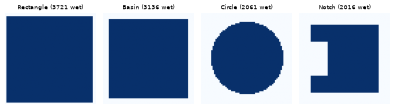

In [6]:
mask_rect = np.zeros((N, N))
mask_rect[1:-2, 1:-2] = 1.0

mask_basin = np.zeros((N, N))
mask_basin[4:-4, 4:-4] = 1.0

mask_circle = ((X - N / 2) ** 2 + (Y - N / 2) ** 2 < (0.4 * N) ** 2).astype(float)

mask_notch = np.zeros((N, N))
mask_notch[8:-8, 8:-8] = 1.0
mask_notch[20:44, :20] = 0.0

geometries = {
    "Rectangle": mask_rect,
    "Basin": mask_basin,
    "Circle": mask_circle,
    "Notch": mask_notch,
}

fig, axes = plt.subplots(1, 4, figsize=(8, 2.2), dpi=50)
for ax, (name, mask) in zip(axes, geometries.items(), strict=True):
    ax.imshow(mask, origin="lower", cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{name} ({int(mask.sum())} wet)", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Rectangle: Spectral, CG, Multigrid

With no land the problem is a pure Dirichlet box, and all four of the following solve the same discrete problem.

### Spectral DST

The DST diagonalises the five-point Laplacian with homogeneous Dirichlet walls, so the solve is a pointwise division by the eigenvalues in frequency space:

$$\hat\psi_{k,l} = \frac{\hat f_{k,l}}{\mu_k + \mu_l - \lambda}$$

It needs no iteration and is exact up to rounding. It is the default `method="spectral"`.

### CG and multigrid

`method="cg"` runs gaussx CG on the masked operator, preconditioned by the spectral solve of the same walls. `method="multigrid"` swaps that preconditioner for one V-cycle of a gridax hierarchy built on the same mask and $\lambda$. Because the right-hand side is a DST eigenvector, unpreconditioned CG converges in 2 iterations. The wrapper's default preconditioner is a spectral solve on the full array, whose wall is not exactly the rectangle's, so on this eigenvector it costs more steps (10) than it saves; on the masked domains below it pays.

Rectangle:


  Spectral      0.64 ms  8.8e-14  direct
  CG (bare)     0.15 ms  7.1e-14  2 iters
  CG            2.50 ms  9.0e-08  10 iters
  Multigrid     2.59 ms  1.6e-07  5 iters
  max |CG - spectral| = 5.0e-11
  max |MG - spectral| = 5.0e-10


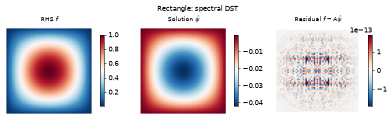

In [7]:
print("Rectangle:")
mask = jnp.asarray(mask_rect)
b = rhs * mask
A = laplace_op(mask)
mg = gridax_jax.build_multigrid_solver(mask_rect, dx, dy, lambda_=lambda_)


def solve(method, **kw):
    return gfd.streamfunction_from_vorticity(
        b, dx, dy, lambda_=lambda_, method=method, **kw
    )


psi_sp = solve("spectral")
psi_cg = solve("cg", mask=mask)
psi_mg = solve("multigrid", mask=mask, multigrid_solver=mg)

_, info0 = cg(A, b)
pc = gridax_jax.make_spectral_preconditioner(dx, dy, lambda_=lambda_, bc="dst")
_, info1 = cg(A, b, pc)
v_cycle = lambda r: mg.v_cycle(jnp.zeros_like(r), r)
_, info2 = cg(A, b, v_cycle)

runs = {
    "Spectral": (psi_sp, lambda: solve("spectral"), "direct"),
    "CG (bare)": (cg(A, b)[0], lambda: cg(A, b)[0], f"{int(info0.iterations)} iters"),
    "CG": (psi_cg, lambda: solve("cg", mask=mask), f"{int(info1.iterations)} iters"),
    "Multigrid": (
        psi_mg,
        lambda: solve("multigrid", mask=mask, multigrid_solver=mg),
        f"{int(info2.iterations)} iters",
    ),
}
results["Rectangle"] = {
    name: {
        "time_ms": 1e3 * time_fn(fn),
        "rel_residual": rel_residual(psi, b, A, mask),
        "label": label,
    }
    for name, (psi, fn, label) in runs.items()
}
for name, r in results["Rectangle"].items():
    print(f"  {name:<10} {r['time_ms']:7.2f} ms  {r['rel_residual']:.1e}  {r['label']}")
print(f"  max |CG - spectral| = {float(jnp.max(jnp.abs(psi_cg - psi_sp))):.1e}")
print(f"  max |MG - spectral| = {float(jnp.max(jnp.abs(psi_mg - psi_sp))):.1e}")

plot_row(b, psi_sp, (b - A(psi_sp)), mask_rect, "Rectangle: spectral DST")

## 4. Basin with a Land Border: Capacitance, CG, Multigrid

A rectangular basin with a four-cell land border. The wet region is smaller than the array, so the plain DST no longer solves the right problem.

### Capacitance matrix (Sherman-Morrison-Woodbury)

The capacitance method extends the spectral solve to a mask. It solves the full-rectangle spectral problem, precomputes the response at each of the $B$ coast points, and removes the error there with a dense $B \times B$ system. The setup costs $B$ spectral solves and an $O(B^3)$ factorisation, and each later solve costs one spectral solve plus an $O(B^2)$ correction, which pays when $B$ is small and the mask is fixed. `gridax_jax.build_capacitance_solver` builds it, and the wrapper takes it as `capacitance_solver=`.

### CG and multigrid

CG uses the masked operator, which zeroes the dry cells, and the multigrid hierarchy coarsens the mask with the grid.

Basin:


  coast points B = 224


  Capacitance    0.78 ms  1.3e-13  direct
  CG (bare)      3.46 ms  4.8e-07  127 iters
  CG             3.11 ms  4.9e-08  13 iters
  Multigrid      2.65 ms  3.3e-08  5 iters
  max |CG - capacitance| = 3.7e-11


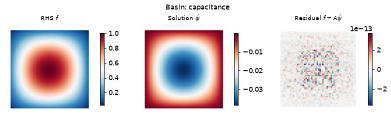

In [8]:
print("Basin:")
mask = jnp.asarray(mask_basin)
b = rhs * mask
A = laplace_op(mask)
cap = gridax_jax.build_capacitance_solver(
    mask_basin.astype(bool), dx, dy, lambda_=lambda_, base_bc="dst"
)
mg = gridax_jax.build_multigrid_solver(mask_basin, dx, dy, lambda_=lambda_)
n_coast = int(gridax_jax.coast_ring(mask.astype(bool)).sum())
print(f"  coast points B = {n_coast}")


def solve(method, **kw):
    return gfd.streamfunction_from_vorticity(
        b, dx, dy, lambda_=lambda_, method=method, **kw
    )


kw_cap = {"capacitance_solver": cap}
kw_cg = {"mask": mask}
kw_mg = {"mask": mask, "multigrid_solver": mg}
psi_cap = solve("capacitance", **kw_cap)
psi_cg = solve("cg", **kw_cg)
psi_mg = solve("multigrid", **kw_mg)

_, info0 = cg(A, b)
_, info1 = cg(A, b, pc)
v_cycle = lambda r: mg.v_cycle(jnp.zeros_like(r), r)
_, info2 = cg(A, b, v_cycle)

runs = {
    "Capacitance": (psi_cap, lambda: solve("capacitance", **kw_cap), "direct"),
    "CG (bare)": (cg(A, b)[0], lambda: cg(A, b)[0], f"{int(info0.iterations)} iters"),
    "CG": (psi_cg, lambda: solve("cg", **kw_cg), f"{int(info1.iterations)} iters"),
    "Multigrid": (
        psi_mg,
        lambda: solve("multigrid", **kw_mg),
        f"{int(info2.iterations)} iters",
    ),
}
results["Basin"] = {
    name: {
        "time_ms": 1e3 * time_fn(fn),
        "rel_residual": rel_residual(psi, b, A, mask),
        "label": label,
    }
    for name, (psi, fn, label) in runs.items()
}
for name, r in results["Basin"].items():
    print(f"  {name:<11} {r['time_ms']:7.2f} ms  {r['rel_residual']:.1e}  {r['label']}")
print(f"  max |CG - capacitance| = {float(jnp.max(jnp.abs(psi_cg - psi_cap))):.1e}")

plot_row(b, psi_cap, (b - A(psi_cap)), mask_basin, "Basin: capacitance")

## 5. Circular Basin: CG and Multigrid

A disk of radius $0.4\,N$ cells. The capacitance method still applies, but its setup grows with the number of coast points, which scales with the circumference, so here we compare the iterative methods only. CG iterates in a Krylov subspace and the preconditioner decides how many steps it takes; the multigrid V-cycle respects the circular mask at every level.

Circle:
  coast points B = 148


  CG (bare)     3.02 ms  5.6e-07  110 iters
  CG            3.60 ms  3.0e-08  16 iters
  Multigrid     2.57 ms  1.7e-08  5 iters
  max |CG - MG| = 2.5e-11


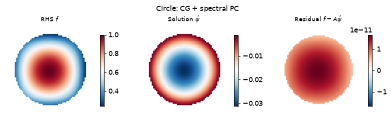

In [9]:
print("Circle:")
mask = jnp.asarray(mask_circle)
b = rhs * mask
A = laplace_op(mask)
mg = gridax_jax.build_multigrid_solver(mask_circle, dx, dy, lambda_=lambda_)
n_coast = int(gridax_jax.coast_ring(mask.astype(bool)).sum())
print(f"  coast points B = {n_coast}")


def solve(method, **kw):
    return gfd.streamfunction_from_vorticity(
        b, dx, dy, lambda_=lambda_, method=method, **kw
    )


kw_cg = {"mask": mask}
kw_mg = {"mask": mask, "multigrid_solver": mg}
psi_cg = solve("cg", **kw_cg)
psi_mg = solve("multigrid", **kw_mg)

_, info0 = cg(A, b)
_, info1 = cg(A, b, pc)
v_cycle = lambda r: mg.v_cycle(jnp.zeros_like(r), r)
_, info2 = cg(A, b, v_cycle)

runs = {
    "CG (bare)": (cg(A, b)[0], lambda: cg(A, b)[0], f"{int(info0.iterations)} iters"),
    "CG": (psi_cg, lambda: solve("cg", **kw_cg), f"{int(info1.iterations)} iters"),
    "Multigrid": (
        psi_mg,
        lambda: solve("multigrid", **kw_mg),
        f"{int(info2.iterations)} iters",
    ),
}
results["Circle"] = {
    name: {
        "time_ms": 1e3 * time_fn(fn),
        "rel_residual": rel_residual(psi, b, A, mask),
        "label": label,
    }
    for name, (psi, fn, label) in runs.items()
}
for name, r in results["Circle"].items():
    print(f"  {name:<10} {r['time_ms']:7.2f} ms  {r['rel_residual']:.1e}  {r['label']}")
print(f"  max |CG - MG| = {float(jnp.max(jnp.abs(psi_cg - psi_mg))):.1e}")

plot_row(b, psi_cg, (b - A(psi_cg)) * mask, mask_circle, "Circle: CG + spectral PC")

## 6. Notch with a Variable Coefficient: Multigrid and MG-preconditioned CG

The hardest case combines an irregular mask with a spatially varying diffusion coefficient:

$$\nabla \cdot \bigl(c(x, y)\,\nabla \psi\bigr) - \lambda\,\psi = f, \qquad c(x, y) = 1 + 0.8\sin(2\pi x / N_x)$$

`sesmax_core.gfd` solves the constant-coefficient problem only, so this section stays on gridax: `gridax_jax.build_multigrid_solver(..., coeff=...)` is used on its own, and gaussx CG runs on the same operator. The domain is the rectangle with eight-cell walls and the notch cut from the left.

### Multigrid standalone

The coefficient enters through face-averaged diffusivities, and multigrid coarsens both the mask and the coefficient. We take 10 V-cycles, more than in a constant-coefficient problem, because the variable coefficient raises the condition number.

### MG-preconditioned CG

For a tight tolerance, the V-cycle serves as the CG preconditioner. The operator must be the one the hierarchy was built with, so we take its flat matvec from the finest level of `solver.as_preconditioner(dtype)`, wrap it with `gaussx.as_linear_operator(..., shape=(n, n))`, and pass the same object as the gaussx preconditioner. The unpreconditioned CG on the same operator is the baseline.

Notch (variable coefficient):


  CG (bare)    11.20 ms  3.9e-11  317 iters
  Multigrid     3.47 ms  3.6e-11  10 V-cyc
  MG+CG         4.65 ms  1.0e-11  7 iters
  relative difference MG vs MG+CG: 4.9e-12


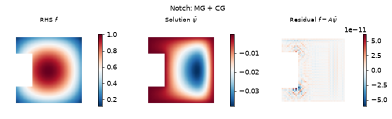

In [10]:
print("Notch (variable coefficient):")
coeff = 1.0 + 0.8 * np.sin(2 * np.pi * X / N)
mask = jnp.asarray(mask_notch)
b = rhs * mask
mg = gridax_jax.build_multigrid_solver(
    mask_notch, dx, dy, lambda_=lambda_, coeff=coeff, n_cycles=10
)
mgp = mg.as_preconditioner(b.dtype)
n = b.size
flat_op = gaussx.as_linear_operator(
    mgp.levels[0].operator.mv, shape=(n, n), dtype=b.dtype, negative_definite=True
)
A = lambda x: flat_op.mv(x.ravel()).reshape(x.shape)
solver = gaussx.CGSolver(rtol=1e-10, atol=1e-10, max_steps=500)


def flat_cg(preconditioner=None):
    x, info = gaussx.linear_solve_with_info(
        flat_op, b.ravel(), solver=solver, preconditioner=preconditioner
    )
    return x.reshape(b.shape) * mask, info


psi_cg0, info0 = flat_cg()
psi_mg = mg(b)
psi_mgcg, info1 = flat_cg(mgp)

runs = {
    "CG (bare)": (psi_cg0, lambda: flat_cg()[0], f"{int(info0.iterations)} iters"),
    "Multigrid": (psi_mg, lambda: mg(b), "10 V-cyc"),
    "MG+CG": (psi_mgcg, lambda: flat_cg(mgp)[0], f"{int(info1.iterations)} iters"),
}
results["Notch"] = {
    name: {
        "time_ms": 1e3 * time_fn(fn),
        "rel_residual": rel_residual(psi, b, A, mask),
        "label": label,
    }
    for name, (psi, fn, label) in runs.items()
}
for name, r in results["Notch"].items():
    print(f"  {name:<10} {r['time_ms']:7.2f} ms  {r['rel_residual']:.1e}  {r['label']}")
diff = jnp.linalg.norm(psi_mgcg - psi_mg) / jnp.linalg.norm(psi_mgcg)
print(f"  relative difference MG vs MG+CG: {float(diff):.1e}")

plot_row(b, psi_mgcg, (b - A(psi_mgcg)) * mask, mask_notch, "Notch: MG + CG")

## 7. Accuracy and Timing

The bars compare the relative residual $\|f - A\hat\psi\|/\|f\|$ (left, log scale) and the jit-compiled solve time (right) for every geometry and method. Each solve is compiled once, called once to warm up, then timed over five calls. The CG and multigrid methods stop at the wrapper's tolerance $10^{-6}$ (the notch at $10^{-10}$), so their residuals sit below that level (at most $6 \times 10^{-7}$, or $4 \times 10^{-11}$ on the notch) while the direct methods sit at rounding, near $10^{-13}$.

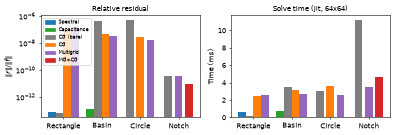

In [11]:
geom_order = list(results)
colors = {
    "Spectral": "C0",
    "Capacitance": "C2",
    "CG (bare)": "C7",
    "CG": "C1",
    "Multigrid": "C4",
    "MG+CG": "C3",
}
xs, cs, ts, rs = [], [], [], []
for gi, geom in enumerate(geom_order):
    names = list(results[geom])
    w = 0.8 / len(names)
    for si, name in enumerate(names):
        xs.append(gi + (si - (len(names) - 1) / 2) * w)
        cs.append(colors[name])
        ts.append(results[geom][name]["time_ms"])
        rs.append(max(results[geom][name]["rel_residual"], 1e-16))

fig, (ax_res, ax_time) = plt.subplots(1, 2, figsize=(8, 2.8), dpi=50)
ax_time.bar(xs, ts, width=0.2, color=cs)
ax_time.set_ylabel("Time (ms)")
ax_time.set_title("Solve time (jit, 64x64)", fontsize=10)
ax_res.bar(xs, rs, width=0.2, color=cs)
ax_res.set_yscale("log")
ax_res.set_ylabel("$\\|r\\| / \\|f\\|$")
ax_res.set_title("Relative residual", fontsize=10)
for ax in (ax_res, ax_time):
    ax.set_xticks(range(len(geom_order)), geom_order)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax_res.legend(handles, colors, fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

## 8. Known Boundary Values

Every solve above has $\psi = 0$ on the coast. When the boundary values $g$ are known and non-zero (a parent model, observations), pass them as `known_values=`: the wrapper lifts them out of the right-hand side, solves the homogeneous problem on the wet cells, and returns $\psi = \tilde g + \psi_{\text{hom}}$, equal to $g$ on the coast ring. The [Known boundary values](inhomogeneous_bcs_tutorial.ipynb) notebook derives the method and covers interior observations, multilayer PV and gradients. Here we only check it on the basin with $g = 0.1\sin(2\pi y)$, for `method="cg"` and for the capacitance solver built on the same wet mask.

coast cells: 224
max |psi - g| on the coast:    0.0e+00
max residual on wet cells:     7.1e-06
max |CG - capacitance|:        5.6e-10


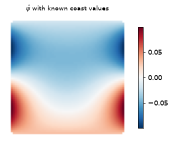

In [12]:
mask = jnp.asarray(mask_basin)
b = rhs * mask
g = jnp.asarray(0.1 * np.sin(2 * np.pi * Y / (N - 2)))
ring = gridax_jax.coast_ring(mask.astype(bool))

psi_cg = gfd.streamfunction_from_vorticity(
    b, dx, dy, lambda_=lambda_, method="cg", mask=mask, known_values=g
)
psi_cap = gfd.streamfunction_from_vorticity(
    b,
    dx,
    dy,
    lambda_=lambda_,
    method="capacitance",
    mask=mask,
    capacitance_solver=gridax_jax.build_capacitance_solver(
        mask_basin.astype(bool), dx, dy, lambda_=lambda_, base_bc="dst"
    ),
    known_values=g,
)
res = (
    b - gridax_jax.masked_laplacian(psi_cg, jnp.ones_like(b), dx, dy, lambda_)
) * mask
print(f"coast cells: {int(ring.sum())}")
print(
    f"max |psi - g| on the coast:    {float(jnp.max(jnp.abs((psi_cg - g)[ring]))):.1e}"
)
print(f"max residual on wet cells:     {float(jnp.max(jnp.abs(res))):.1e}")
print(f"max |CG - capacitance|:        {float(jnp.max(jnp.abs(psi_cg - psi_cap))):.1e}")

full = np.where((mask_basin > 0.5) | np.asarray(ring), np.asarray(psi_cg), np.nan)
fig, ax = plt.subplots(figsize=(3.6, 3), dpi=50)
im = ax.imshow(full, origin="lower", cmap="RdBu_r")
ax.set_title("$\\hat\\psi$ with known coast values", fontsize=9)
ax.axis("off")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

## 9. Summary

| Geometry | Method | Use when | Cost |
|----------|--------|----------|------|
| Rectangle | `"spectral"` | the domain is the full rectangle | $O(N \log N)$, exact |
| Fixed mask, many solves | `"capacitance"` | constant coefficient, few coast points | one spectral solve plus $O(B^2)$ per solve |
| Any mask | `"multigrid"` | tight tolerance, the preconditioner should not depend on grid size | $k$ V-cycles, $k$ independent of $N$ |
| Any mask, no setup | `"cg"` | constant coefficient, nothing to pre-build | $O(k \cdot N \log N)$, $k$ grows with $N$ |
| Variable coefficient | gridax multigrid alone, or in CG | $c(x, y)$ is not constant | outside `sesmax_core.gfd` |

The iteration counts are the clearest measurement at this size (CG tolerance $10^{-6}$, the notch $10^{-10}$). Bare CG takes 2 iterations on the rectangle, whose right-hand side is an eigenvector, but 127 on the basin, 110 on the circle and 317 on the notch. The spectral preconditioner brings the basin to 13 and the circle to 16 iterations, and one multigrid V-cycle brings each of the rectangle, basin and circle to 5. On the notch the V-cycle preconditioner takes 7 iterations against 317, and standalone multigrid with 10 V-cycles reaches a residual of the same size ($4 \times 10^{-11}$ against $1 \times 10^{-11}$). The table below prints these numbers with the timings.

In [13]:
print(
    f"{'Geometry':<10} {'Method':<12} {'Time (ms)':>10} {'Rel. residual':>14}  Detail"
)
print("=" * 62)
for geom in geom_order:
    for name, r in results[geom].items():
        print(
            f"{geom:<10} {name:<12} {r['time_ms']:>10.2f} "
            f"{r['rel_residual']:>14.1e}  {r['label']}"
        )
    print("-" * 62)

Geometry   Method        Time (ms)  Rel. residual  Detail
Rectangle  Spectral           0.64        8.8e-14  direct
Rectangle  CG (bare)          0.15        7.1e-14  2 iters
Rectangle  CG                 2.50        9.0e-08  10 iters
Rectangle  Multigrid          2.59        1.6e-07  5 iters
--------------------------------------------------------------
Basin      Capacitance        0.78        1.3e-13  direct
Basin      CG (bare)          3.46        4.8e-07  127 iters
Basin      CG                 3.11        4.9e-08  13 iters
Basin      Multigrid          2.65        3.3e-08  5 iters
--------------------------------------------------------------
Circle     CG (bare)          3.02        5.6e-07  110 iters
Circle     CG                 3.60        3.0e-08  16 iters
Circle     Multigrid          2.57        1.7e-08  5 iters
--------------------------------------------------------------
Notch      CG (bare)         11.20        3.9e-11  317 iters
Notch      Multigrid          3.47    